# Trip.com Quantitative Valuation

This notebook rebuilds and audits the core FCFF-DCF valuation from a CFA Institute Research Challenge team report. It emphasizes reproducibility, timing consistency, and uncertainty rather than presenting a single target price without validation.

**Questions addressed**

1. Can the published CNY 626.2 target be reproduced from its summary inputs?
2. How does standard terminal-value timing affect the result?
3. Which WACC and terminal-growth assumptions matter most?
4. What range of values appears under explicit Monte Carlo assumptions?

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.valuation import (
    dcf_valuation,
    monte_carlo_prices,
    reported_summary_price,
    sensitivity_table,
    three_stage_ddm,
    weighted_relative_valuation,
)

sns.set_theme(style='whitegrid', context='notebook')
pd.options.display.float_format = '{:,.2f}'.format

## 1. Forecast free cash flow

The model uses the 2025-2033 FCFF path transcribed from the report's valuation appendix. Monetary values are in millions of CNY.

In [2]:
forecast = pd.read_csv(ROOT / 'data' / 'processed' / 'base_case_fcff.csv')
forecast

,year,fcff_mcny
0,2025,"11,252.80"
1,2026,"14,398.80"
2,2027,"16,119.90"
3,2028,"18,106.10"
4,2029,"18,635.40"
5,2030,"20,169.70"
6,2031,"21,907.00"
7,2032,"23,607.10"
8,2033,"26,159.80"


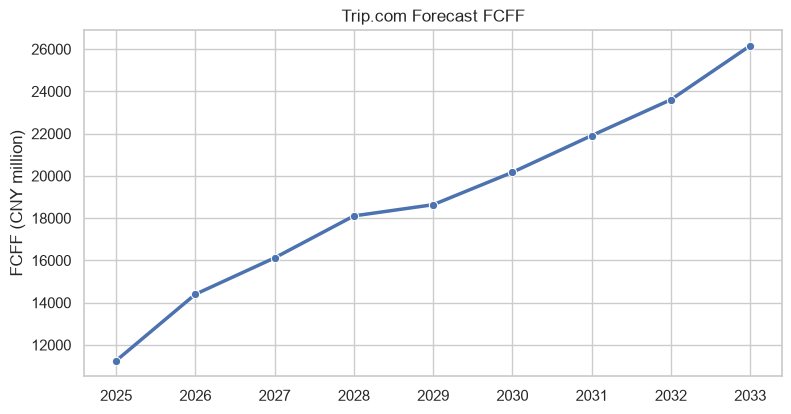

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=forecast, x='year', y='fcff_mcny', marker='o', linewidth=2.5, ax=ax)
ax.set(title='Trip.com Forecast FCFF', xlabel='', ylabel='FCFF (CNY million)')
ax.ticklabel_format(style='plain', axis='x')
plt.show()

## 2. Base-case DCF and timing audit

The source report used a 7.92% WACC, 3.00% terminal growth, CNY 20.382 billion of net cash, and 689 million diluted shares. A negative net-debt value represents net cash.

In [4]:
WACC = 0.0792
TERMINAL_GROWTH = 0.03
NET_DEBT = -20_382.0
SHARES_OUTSTANDING = 689.0
REFERENCE_PRICE = 517.0

fcff = forecast['fcff_mcny'].to_numpy()
standard = dcf_valuation(
    fcff, wacc=WACC, terminal_growth=TERMINAL_GROWTH,
    net_debt=NET_DEBT, shares_outstanding=SHARES_OUTSTANDING
)
source_timing = dcf_valuation(
    fcff, wacc=WACC, terminal_growth=TERMINAL_GROWTH,
    net_debt=NET_DEBT, shares_outstanding=SHARES_OUTSTANDING,
    terminal_discount_periods=8,
)
published_summary = reported_summary_price(
    pv_forecast_fcff=113_312.8, pv_terminal_value=297_756.4,
    net_debt=NET_DEBT, shares_outstanding=SHARES_OUTSTANDING,
)

comparison = pd.DataFrame({
    'Method': [
        'Standard 9-period terminal discount',
        'Source-implied 8-period terminal discount',
        'Published DCF summary',
    ],
    'Implied price (CNY/share)': [
        standard.implied_price, source_timing.implied_price, published_summary
    ],
})
comparison

,Method,Implied price (CNY/share)
0,Standard 9-period terminal discount,594.33
1,Source-implied 8-period terminal discount,626.03
2,Published DCF summary,626.20


### Interpretation

The published summary is internally reproducible at approximately CNY 626.2. However, discounting the terminal value for the full nine forecast periods produces a lower CNY 594.3 result. The roughly CNY 32/share difference is primarily a timing issue, not a change in operating assumptions. Because terminal value represents more than 70% of enterprise value, this convention is economically material and should be disclosed.

## 3. Sensitivity analysis

The table below recalculates the standard nine-period DCF across the report's WACC and terminal-growth ranges.

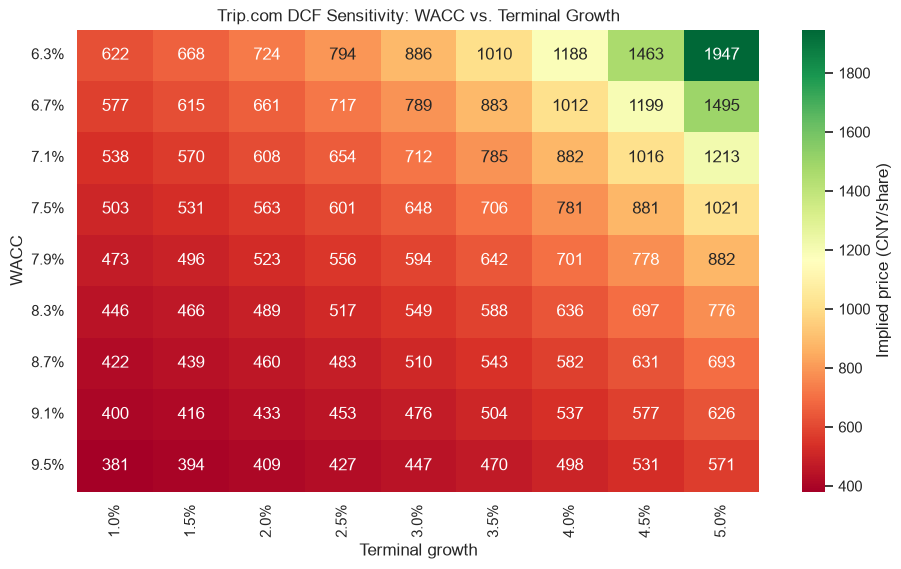

In [5]:
wacc_values = np.arange(0.0632, 0.0953, 0.004)
growth_values = np.arange(0.01, 0.0501, 0.005)
sensitivity = sensitivity_table(
    fcff, wacc_values=wacc_values, growth_values=growth_values,
    net_debt=NET_DEBT, shares_outstanding=SHARES_OUTSTANDING,
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(sensitivity, annot=True, fmt='.0f', cmap='RdYlGn',
            cbar_kws={'label': 'Implied price (CNY/share)'}, ax=ax)
ax.set(
    title='Trip.com DCF Sensitivity: WACC vs. Terminal Growth',
    xlabel='Terminal growth', ylabel='WACC',
)
ax.set_xticklabels([f'{x:.1%}' for x in sensitivity.columns])
ax.set_yticklabels([f'{x:.1%}' for x in sensitivity.index], rotation=0)
plt.show()

## 4. Monte Carlo valuation

This simplified simulation varies WACC, terminal growth, and the level of the complete FCFF path. A fixed seed makes every result reproducible. These explicit distributions are educational assumptions; they do not claim to reconstruct undisclosed workbook formulas.

In [6]:
prices = monte_carlo_prices(
    fcff, simulations=10_000, base_wacc=WACC, wacc_std=0.005,
    base_terminal_growth=TERMINAL_GROWTH, terminal_growth_std=0.0035,
    fcff_scale_std=0.04, net_debt=NET_DEBT,
    shares_outstanding=SHARES_OUTSTANDING, seed=42,
)

simulation_summary = pd.Series({
    'Median price': np.median(prices),
    '5th percentile': np.percentile(prices, 5),
    '95th percentile': np.percentile(prices, 95),
    'Probability above CNY 517': (prices > REFERENCE_PRICE).mean(),
})
simulation_summary

Median price                595.52
5th percentile              496.01
95th percentile             744.97
Probability above CNY 517     0.89
dtype: float64

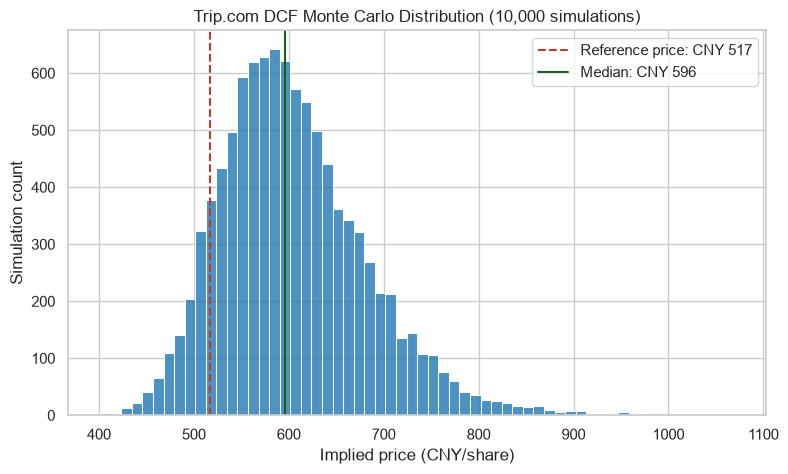

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(prices, bins=60, color='#1f77b4', alpha=0.8, ax=ax)
ax.axvline(REFERENCE_PRICE, color='#c0392b', linestyle='--',
           label='Reference price: CNY 517')
ax.axvline(np.median(prices), color='#1b5e20',
           label=f'Median: CNY {np.median(prices):.0f}')
ax.set(
    title='Trip.com DCF Monte Carlo Distribution (10,000 simulations)',
    xlabel='Implied price (CNY/share)', ylabel='Simulation count',
)
ax.legend()
plt.show()

## 5. Dividend discount model cross-check

The report also values Trip.com with a three-stage dividend discount model. The first stage uses disclosed 2025-2033 dividends; a nine-year transition then converges to each scenario's stable payout, growth, and cost-of-equity assumptions.

In [8]:
ddm_inputs = pd.read_csv(ROOT / 'data/processed/ddm_inputs.csv')
ddm_scenarios = pd.read_csv(ROOT / 'data/processed/ddm_scenarios.csv')

ddm_rows = []
for scenario in ddm_scenarios.itertuples(index=False):
    result = three_stage_ddm(
        ddm_inputs['dps_cny'],
        initial_cost_of_equity=ddm_inputs['cost_of_equity'].iloc[-1],
        ending_eps=ddm_inputs['eps_cny'].iloc[-1],
        transition_years=9,
        starting_eps_growth=0.09,
        starting_payout_ratio=ddm_inputs['payout_ratio'].iloc[-1],
        stable_eps_growth=scenario.stable_eps_growth,
        stable_payout_ratio=scenario.stable_payout_ratio,
        stable_cost_of_equity=scenario.stable_cost_of_equity,
    )
    ddm_rows.append({
        'Scenario': scenario.scenario,
        'Published price': scenario.published_price_cny,
        'Modeled price': result.implied_price,
        'Difference': result.implied_price - scenario.published_price_cny,
    })

ddm_results = pd.DataFrame(ddm_rows).set_index('Scenario')
ddm_results

,Published price,Modeled price,Difference
Scenario,,,
Bear,409.60,430.11,20.51
Base,583.30,585.81,2.51
Bull,647.60,643.43,-4.17


## 6. Relative valuation and scenario comparison

The report's EV/EBITDA, EV/EBIT, and P/E outputs are combined using disclosed weights. The football field compares DCF, DDM, relative valuation, and the Monte Carlo range against the CNY 517 reference price.

,method,multiple,forecast_metric_mcny,implied_price_cny,weight
0,EV/EBITDA,22.48,17973,615.90,0.75
1,EV/EBIT,27.65,17991,751.60,0.20
2,P/E,37.03,19633,"1,055.10",0.05


Weighted relative valuation: CNY 665.0 per share


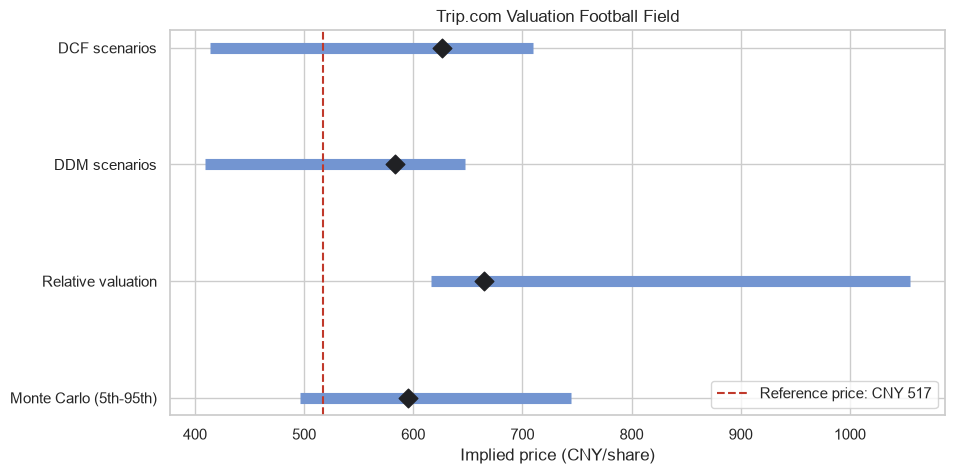

In [9]:
relative = pd.read_csv(ROOT / 'data/processed/relative_valuation.csv')
relative_value = weighted_relative_valuation(
    relative['implied_price_cny'], relative['weight']
)
display(relative)
print(f'Weighted relative valuation: CNY {relative_value:,.1f} per share')

football_field = pd.read_csv(ROOT / 'data/processed/football_field.csv')
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(football_field))
for i, row in football_field.iterrows():
    ax.hlines(i, row['low'], row['high'], color='#7395d1', linewidth=8)
    ax.scatter(row['mid'], i, marker='D', s=90, color='#202124', zorder=3)
ax.axvline(REFERENCE_PRICE, color='#c0392b', linestyle='--', label='Reference price: CNY 517')
ax.set_yticks(y, football_field['method'])
ax.invert_yaxis()
ax.set(title='Trip.com Valuation Football Field', xlabel='Implied price (CNY/share)')
ax.legend(loc='lower right')
plt.show()

## 7. Takeaways

- The published CNY 626.2 summary can be reproduced from its disclosed components.
- A conventional nine-period terminal-value discount gives CNY 594.3, demonstrating why valuation timing must be audited.
- The three-stage DDM reproduces the published base case within 1%, while the weighted relative valuation equals CNY 665.0.
- Bear/base/bull cases across DCF and DDM span roughly CNY 410-710, illustrating the decision impact of growth, margin, payout, and discount-rate assumptions.
- Terminal value contributes most of enterprise value, so WACC and perpetual growth dominate the sensitivity analysis.
- Under the stated simulation assumptions, the distribution is right-skewed and should be interpreted as a range rather than a precise forecast.
- This notebook is an educational portfolio analysis and not investment advice.